In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import seaborn as sns
from glob import glob
import subprocess
import tempfile
from os.path import dirname

/gpfs/home/qcf21tku/.conda/envs/bio/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.25.2
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/

Bdb.csv  genomeInfo.csv		Mdb.csv  Sdb.csv  Widb.csv
Cdb.csv  genomeInformation.csv	Ndb.csv  Wdb.csv


In [3]:
! wc -l /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/*

    334 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Bdb.csv
    334 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Cdb.csv
    358 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/genomeInfo.csv
    358 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/genomeInformation.csv
 110890 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Mdb.csv
   9450 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Ndb.csv
    334 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Sdb.csv
    240 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Wdb.csv
    240 /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Widb.csv
 122538 total


In [4]:
df_tax = pd.read_csv(
    "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/all_taxonomy_v3.tsv", 
    sep = '\t', 
    index_col = 0
)[['bin_id', 'taxonomy_refined_2']]

In [5]:
df_clust = pd.read_csv(
    "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_drep_99/data_tables/Cdb.csv"
)[['genome', 'secondary_cluster', 'primary_cluster']]

In [6]:
QUALS_PATH = "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_eukcc/euk_eukcc_all_quals.csv"

In [7]:
df_batch = pd.read_csv(
    "/gpfs/home/qcf21tku/my_code/mosaic-workflows/config/samples.tsv", sep = '\t'
)[
    ['img_taxon_id', 'batch']
]

df_batch['img_taxon_id'] = df_batch.img_taxon_id.apply(str)
df_batch.head()

,img_taxon_id,batch
0,3300064025,I11_1
1,3300070892,I11_1
2,3300060868,I11_1
3,3300074355,I11_1
4,3300065462,E11_1


In [8]:
def get_sample_from_genome(name):
    
    if '33000' in name:
        idx = name.find('33000')
        return name[idx:idx + 10]
    
    else:
        return name[:5]
    
def fix_batch(row):
    
    if pd.isna(row.batch):
        if row.sample_id[0] in "EI":
            return row.sample_id
        else:
            return "E13_1"
    else:
        return row.batch
    
def get_binning_type(genome_name):
    if genome_name.find('33000') == 0:
        binner = genome_name.split("_")[1]
        if 'merged' in binner:
            return 'manual_multi'
        if binner[0] in "Smv":
            if binner[0] == 'm':
                return 'mbat_single'
            return binner + "_single"
        else:
            return "mbat" + "_single"

    if genome_name.find('33000') > 0:
        if 'mbat' in genome_name:
            return 'mbat_multi'
        if 'vae' in genome_name:
            return 'vae_multi'
        if 'mcl' in genome_name:
            return 'mcl_multi'
        else:
            return 'manual_multi'

    else:
        if 'mbat' in genome_name:
            return 'mbat_coa'
        if 'vae' in genome_name:
            return 'vae_coa'
        if ('mcl' in genome_name) and not ('split' in genome_name):
            return 'mcl_coa'
        else:
            return 'manual_coa'

In [9]:
df = pd.read_csv(QUALS_PATH)
df['sample_id'] = df.genome.apply(get_sample_from_genome)

df = pd.merge(
    df, 
    df_batch, 
    how = 'left', 
    left_on = 'sample_id', 
    right_on = 'img_taxon_id'
).drop(columns = ['img_taxon_id'])

df['batch'] = df.apply(fix_batch, axis = 1)
df['binning_and_type'] = df.genome.apply(get_binning_type)

df['binner'] = df.binning_and_type.apply(lambda x: x.split('_')[0])
df['assembly'] = df.binning_and_type.apply(lambda x: x.split('_')[1])

df.head()

,genome,completeness,contamination,sample_id,batch,binning_and_type,binner,assembly
0,mbat_multi.2_3300055289.fna,41.18,11.76,3300055289,E01_2,mbat_multi,mbat,multi
1,metazoa.1.split_1_v1_3300055289.fna,44.12,11.76,3300055289,E01_2,manual_multi,manual,multi
2,metazoa.1.split_1_v1.fna,47.06,14.71,metaz,E13_1,manual_coa,manual,coa
3,mbat_multi.19_3300045738.fna,34.62,0.00,3300045738,E02_1,mbat_multi,mbat,multi
4,euglenozoa.1.split_1_v1_3300045738.fna,34.62,0.00,3300045738,E02_1,manual_multi,manual,multi


In [10]:
BATCHES = sorted(list(set(df.batch)))

In [11]:
df2 = pd.merge(df, df_clust, on = 'genome', how = 'left').fillna('0_0')
df2['bin_id'] = df2.genome.apply(lambda x: x.rstrip('.fna'))

In [12]:
df3 = pd.merge(df2, df_tax, on = 'bin_id', how = 'left')
df3 = df3[(df3.completeness > 30) & (df3.contamination < 15)]

In [13]:
df_e061 = df3[(df3.batch == "E06_1")]
df_i041 = df3[(df3.batch == "I04_1")]

In [14]:
df_e061[df_e061.binner != 'manual']

,genome,completeness,contamination,sample_id,batch,binning_and_type,binner,assembly,secondary_cluster,primary_cluster,bin_id,taxonomy_refined_2
10,mbat_multi.102_3300071295.fna,35.03,6.37,3300071295,E06_1,mbat_multi,mbat,multi,9_0,9.0,mbat_multi.102_3300071295,other eukaryotes
330,3300056912_vae_2945.fna,94.80,1.00,3300056912,E06_1,vae_single,vae,single,41_2,41.0,3300056912_vae_2945,Micromonas
331,3300056912_mbat.67.fna,58.80,0.00,3300056912,E06_1,mbat_single,mbat,single,0_0,0_0,3300056912_mbat.67,NaN
332,3300056912_mbat.87.fna,56.98,1.42,3300056912,E06_1,mbat_single,mbat,single,0_0,0_0,3300056912_mbat.87,NaN
333,3300056912_SemiBin_15.fna,76.00,0.20,3300056912,E06_1,SemiBin_single,SemiBin,single,0_0,0_0,3300056912_SemiBin_15,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
649,3300061567_28.fna,94.60,0.40,3300061567,E06_1,mbat_single,mbat,single,41_2,41.0,3300061567_28,Micromonas
650,3300061567_50.fna,79.20,1.99,3300061567,E06_1,mbat_single,mbat,single,0_0,0_0,3300061567_50,NaN
651,3300061567_57.fna,82.20,2.40,3300061567,E06_1,mbat_single,mbat,single,40_1,40.0,3300061567_57,Micromonas
662,3300071295_116.fna,80.06,1.14,3300071295,E06_1,mbat_single,mbat,single,0_0,0_0,3300071295_116,NaN


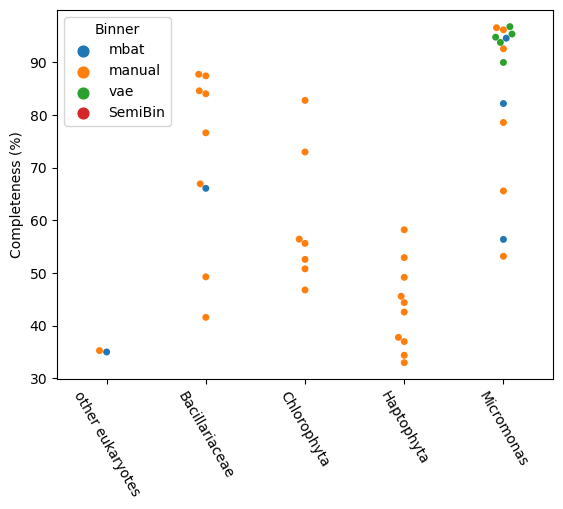

In [15]:
ax1 = sns.swarmplot(
    data = df_e061, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'binner', 
    #hue_order = ['coa', 'multi', 'single'], 
)
ax1.set(xlabel='', ylabel='Completeness (%)')

ax1.tick_params(axis='x', rotation=-60)
plt.legend(title='Binner')
#plt.savefig("/gpfs/home/qcf21tku/scratch/refine_chap/svgs/df_e061_binner_tr2_completeness.svg")

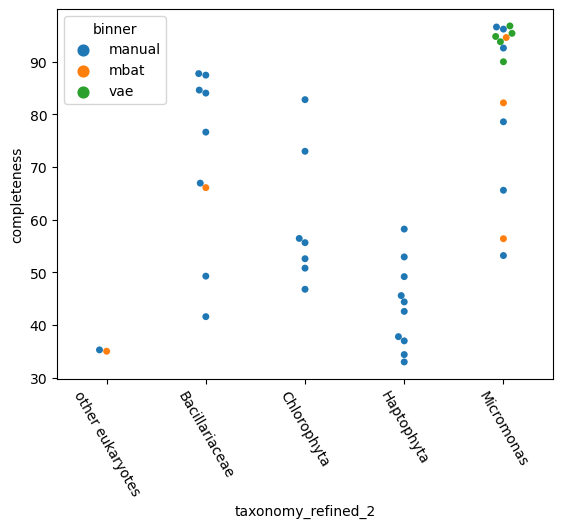

In [16]:
ax2 = sns.swarmplot(
    data = df_e061, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'binner', 
    hue_order = ['manual', 'mbat', 'vae']
)

ax2.tick_params(axis='x', rotation=-60)

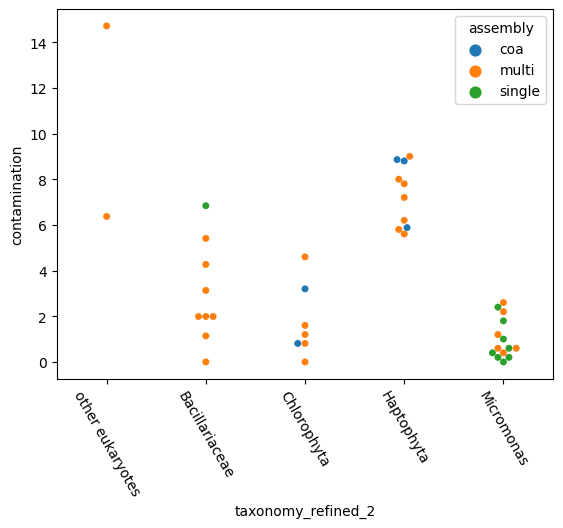

In [17]:
ax3 = sns.swarmplot(
    data = df_e061, 
    y = 'contamination', 
    x = 'taxonomy_refined_2', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single']
)

ax3.tick_params(axis='x', rotation=-60)

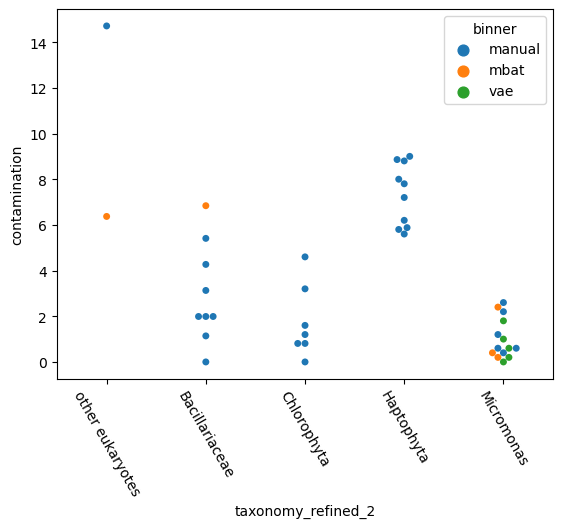

In [18]:
ax4 = sns.swarmplot(
    data = df_e061, 
    y = 'contamination', 
    x = 'taxonomy_refined_2', 
    hue = 'binner', 
    hue_order = ['manual', 'mbat', 'vae']
)

ax4.tick_params(axis='x', rotation=-60)

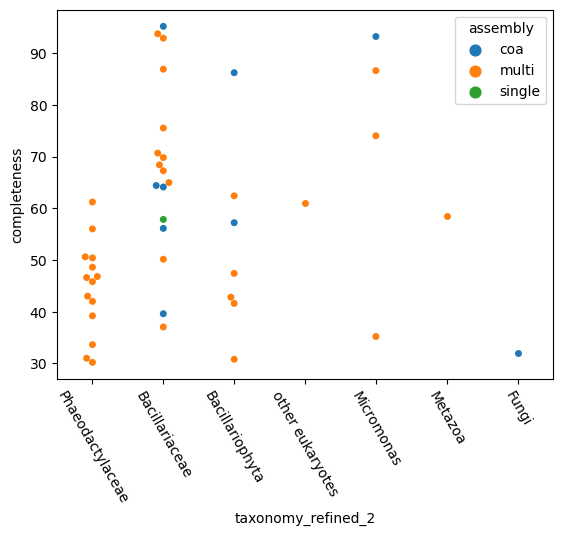

In [19]:
sns.swarmplot(
    data = df_i041, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single']
)

plt.tick_params(axis='x', rotation=-60)

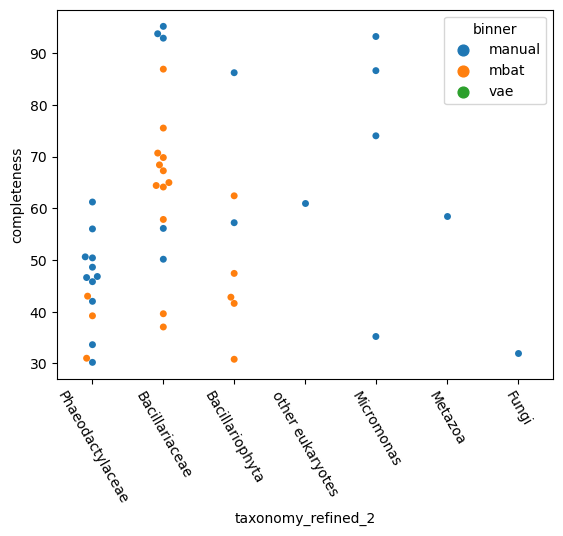

In [20]:
sns.swarmplot(
    data = df_i041, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'binner', 
    hue_order = ['manual', 'mbat', 'vae']
)

plt.tick_params(axis='x', rotation=-60)

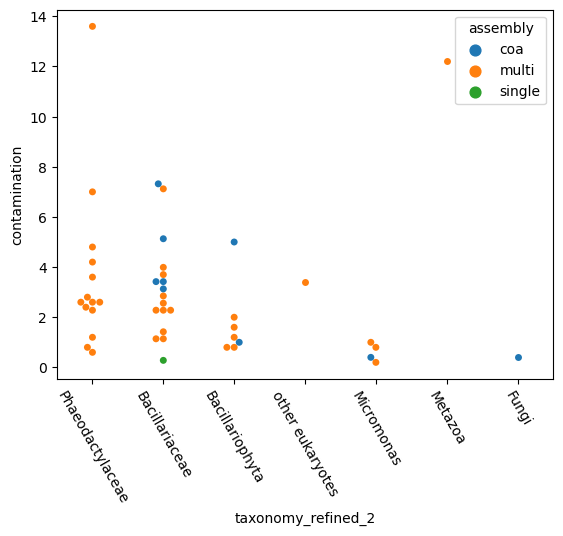

In [21]:
sns.swarmplot(
    data = df_i041, 
    y = 'contamination', 
    x = 'taxonomy_refined_2', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single']
)

plt.tick_params(axis='x', rotation=-60)

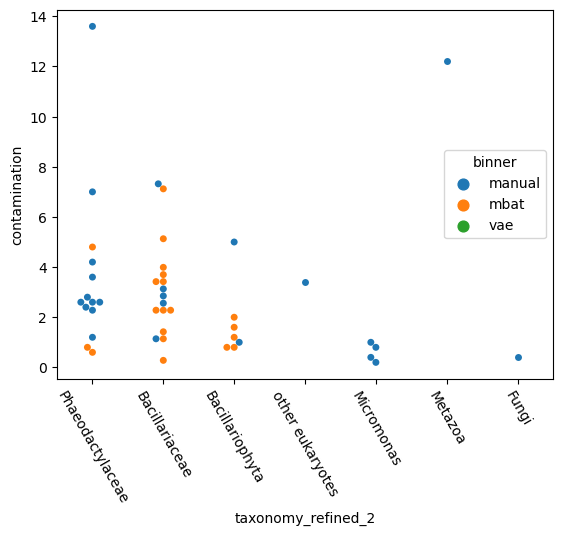

In [22]:
sns.swarmplot(
    data = df_i041, 
    y = 'contamination', 
    x = 'taxonomy_refined_2', 
    hue = 'binner', 
    hue_order = ['manual', 'mbat', 'vae']
)

plt.tick_params(axis='x', rotation=-60)

In [23]:
! grep '3300055289' /gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_eukcc/euk_deduplications.txt

mbat_multi.2_3300055289.fna	mbat_multi.2_3300055289.fna	12678
mbat_multi.2_3300055289.fna	metazoa.1.split_1_v1_3300055289.fna	11963
metazoa.1.split_1_v1_3300055289.fna	mbat_multi.2_3300055289.fna	11963
metazoa.1.split_1_v1_3300055289.fna	metazoa.1.split_1_v1_3300055289.fna	16210


In [24]:
dup_groups = dict()
with open('/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_eukcc/euk_deduplications.txt', 'r') as dup_file:
    for line in dup_file:
        
        # start node, end node, linkage
        g1, g2, n = line.split('\t')
        n = int(n)
        
        # get the sample id
        gid_start = g1.find('33000')
        gid = g1[gid_start:gid_start + 10]
        
        # if we're starting on a new sample, initialise
        if not gid in dup_groups:
            dup_groups[gid] = []
            seen_before = set()
        
        # if the linkage is low, add the mags to new separate groups
        # unless they've already been seen before
        if (n < 100):
            if not g1 in seen_before:
                dup_groups[gid].append(set([g1]))
            if (not g2 in seen_before) and (g1 != g2):
                dup_groups[gid].append(set([g2]))
        
        # otherwise, if the linkage is high, put them in the same group
        else:         
            
            # enumerate all cases - this is a slightly bad case, fix
            if (g1 in seen_before) and (g2 in seen_before) and (g1 != g2):
                for gp in dup_groups[gid]:
                    if g2 in gp:
                        gp.remove(g2)
                    if g1 in gp:
                        gp.add(g2)
                      
            if (g1 in seen_before) and (not g2 in seen_before):
                for gp in dup_groups[gid]:
                    if g1 in gp:
                        gp.add(g2)
            if (g2 in seen_before) and (not g1 in seen_before):
                for gp in dup_groups[gid]:
                    if g2 in gp:
                        gp.add(g1)
            
            if (not g1 in seen_before) and (not g2 in seen_before):
                dup_groups[gid].append(set([g1, g2]))
        
        seen_before.add(g1)
        seen_before.add(g2)
           
            
# filter non-empty
dup_groups = {
    k: [x for x in v if x] for k,v in dup_groups.items()
}

dup_group_items = []
for v in dup_groups.values():
    for v1 in v:
        dup_group_items.append(v1)

In [25]:
dup_groups_coa = dict()
with open('/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/euk_eukcc/euk_deduplications_coa.txt', 'r') as dup_file:
    for line in dup_file:
        
        # start node, end node, linkage
        g1, g2, n = line.split('\t')
        n = int(n)
        
        # get the sample id
        gid = "_".join(g1.split("_")[:2])
        
        # if we're starting on a new sample, initialise
        if not gid in dup_groups_coa:
            dup_groups_coa[gid] = []
            seen_before = set()
        
        # if the linkage is low, add the mags to new separate groups
        # unless they've already been seen before
        if (n < 100):
            if not g1 in seen_before:
                dup_groups_coa[gid].append(set([g1]))
            if (not g2 in seen_before) and (g1 != g2):
                dup_groups_coa[gid].append(set([g2]))
        
        # otherwise, if the linkage is high, put them in the same group
        else:         
            
            # enumerate all cases - this is a slightly bad case, fix
            if (g1 in seen_before) and (g2 in seen_before) and (g1 != g2):
                for gp in dup_groups_coa[gid]:
                    if g2 in gp:
                        gp.remove(g2)
                    if g1 in gp:
                        gp.add(g2)
                      
            if (g1 in seen_before) and (not g2 in seen_before):
                for gp in dup_groups_coa[gid]:
                    if g1 in gp:
                        gp.add(g2)
            if (g2 in seen_before) and (not g1 in seen_before):
                for gp in dup_groups_coa[gid]:
                    if g2 in gp:
                        gp.add(g1)
            
            if (not g1 in seen_before) and (not g2 in seen_before):
                dup_groups_coa[gid].append(set([g1, g2]))
        
        seen_before.add(g1)
        seen_before.add(g2)
           
            
# filter non-empty
dup_groups_coa = {
    k: [x for x in v if x] for k,v in dup_groups_coa.items()
}

dup_group_items_coa = []
for v in dup_groups_coa.values():
    for v1 in v:
        dup_group_items_coa.append(v1)

In [26]:
sum(len(x) for x in dup_group_items)

647

In [27]:
sum(len(x) for x in dup_group_items_coa)

142

In [28]:
dup_groups_all = dup_group_items + dup_group_items_coa

In [29]:
sc_map = dict(zip(
    df3.genome, 
    df3.secondary_cluster, 
))

tx_map = dict(zip(
    df3.genome, 
    df3.taxonomy_refined_2, 
))

In [30]:
def add_clusters(row):
    
    if row.secondary_cluster != "0_0":
        return row.secondary_cluster
    
    if (row.genome in sc_map) and (sc_map.get(row.genome) == "0_0"):
        for grp in dup_groups_all:
            if row.genome in grp:
                for g in grp:
                    if sc_map.get(g) != "0_0":
                        return sc_map.get(g)
                
    return "0_0"
    
    
def add_taxonomy_3(row):
    
    if not pd.isna(row.taxonomy_refined_2):
        return row.taxonomy_refined_2
    
    if (row.genome in tx_map) and pd.isna(tx_map.get(row.genome)):
        for grp in dup_groups_all:
            if row.genome in grp:
                for g in grp:
                    if not pd.isna(tx_map.get(g)):
                        return tx_map.get(g)
                
    return None

df3['tertiary_cluster'] = df3.apply(add_clusters, axis = 1)
df3['taxonomy_refined_3'] = df3.apply(add_taxonomy_3, axis = 1)

In [31]:
df_e061_v2 = df3[(df3.batch == "E06_1")]

df_e061_v2['usage'] = df_e061_v2.taxonomy_refined_2.apply(lambda x: 2 if pd.isna(x) else 5)


df_i041_v2 = df3[(df3.batch == "I04_1")]

df_i041_v2['usage'] = df_i041_v2.taxonomy_refined_2.apply(lambda x: 2 if pd.isna(x) else 5)


/tmp/ipykernel_4720/2798905129.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_e061_v2['usage'] = df_e061_v2.taxonomy_refined_2.apply(lambda x: 2 if pd.isna(x) else 5)
/tmp/ipykernel_4720/2798905129.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_i041_v2['usage'] = df_i041_v2.taxonomy_refined_2.apply(lambda x: 2 if pd.isna(x) else 5)


In [32]:
df_e061_v2.shape, df_i041_v2.shape

((116, 15), (91, 15))

In [33]:
df_e061_v2.groupby('assembly').describe()

completeness                                                        \
                count       mean        std    min      25%    50%      75%   
assembly                                                                      
coa               6.0  60.470000  10.187184  49.20  53.8175  57.34  69.3075   
multi            39.0  66.854872  24.041608  33.00  43.5000  66.95  91.2000   
single           71.0  65.981268  22.281082  31.05  45.2000  68.40  86.1000   

               contamination            ...               usage            \
           max         count      mean  ...    75%    max count      mean   
assembly                                ...                                 
coa       73.0           6.0  5.125000  ...  8.070   8.86   6.0  4.500000   
multi     96.6          39.0  3.308205  ...  5.505  14.71  39.0  4.153846   
single    96.8          71.0  0.798169  ...  0.825   6.84  71.0  2.380282   

                                             
               std  min  25%  50%  75%  max  
assembly                                     
coa       1.224745  2.0  5.0  5.0  5.0  5.0  
multi     1.367642  2.0  2.0  5.0  5.0  5.0  
single    1.005218  2.0  2.0  2.0  2.0  5.0  

[3 rows x 24 columns]

In [34]:
df_e061_v2.groupby('binner').describe()

completeness                                                         \
               count       mean        std    min      25%     50%      75%   
binner                                                                        
SemiBin         16.0  56.656875  18.889136  34.80  39.6675  48.715  77.0500   
manual          44.0  66.707500  22.471519  33.00  46.5000  66.275  88.3625   
mbat            46.0  62.721522  21.660136  31.05  44.7975  61.880  80.5225   
vae             10.0  92.800000   4.379751  81.40  93.0500  94.300  94.7000   

              contamination            ...              usage            \
          max         count      mean  ...   75%    max count      mean   
binner                                 ...                                
SemiBin  82.2          16.0  0.140625  ...  0.20   0.57  16.0  2.000000   
manual   96.6          44.0  3.486364  ...  5.65  14.71  44.0  4.181818   
mbat     94.6          46.0  1.091087  ...  1.42   6.84  46.0  2.326087   
vae      96.8          10.0  1.060000  ...  1.15   5.00  10.0  3.500000   

                                            
              std  min  25%  50%  75%  max  
binner                                      
SemiBin  0.000000  2.0  2.0  2.0  2.0  2.0  
manual   1.351532  2.0  2.0  5.0  5.0  5.0  
mbat     0.944089  2.0  2.0  2.0  2.0  5.0  
vae      1.581139  2.0  2.0  3.5  5.0  5.0  

[4 rows x 24 columns]

In [35]:
df_i041_v2.groupby('assembly').describe()

completeness                                                         \
                count       mean        std    min      25%     50%      75%   
assembly                                                                       
coa              14.0  70.137857  23.926767  31.80  56.3750  73.935  92.4000   
multi            59.0  55.225932  18.182657  30.20  42.9000  49.800  67.6650   
single           18.0  51.195556  16.768204  31.34  36.3225  49.740  57.9575   

                contamination            ...                usage            \
            max         count      mean  ...     75%    max count      mean   
assembly                                 ...                                  
coa       95.16          14.0  2.551429  ...  3.4200   7.32  14.0  3.928571   
multi     93.73          59.0  3.120000  ...  3.4000  13.60  59.0  3.779661   
single    87.75          18.0  0.645000  ...  0.7875   2.85  18.0  2.166667   

                                             
               std  min  25%  50%  75%  max  
assembly                                     
coa       1.491735  2.0  2.0  5.0  5.0  5.0  
multi     1.486349  2.0  2.0  5.0  5.0  5.0  
single    0.707107  2.0  2.0  2.0  2.0  5.0  

[3 rows x 24 columns]

In [36]:
df_i041_v2.groupby('binner').describe()

completeness                                                        \
               count       mean        std    min     25%     50%      75%   
binner                                                                       
SemiBin         10.0  42.589000   9.921294  31.34  35.325  39.315  47.3325   
manual          32.0  58.488750  20.090710  30.20  46.400  53.300  69.5675   
mbat            46.0  57.491087  18.739488  30.77  42.850  56.265  70.2500   
vae              3.0  73.220000  35.049696  32.76  62.680  92.600  93.4500   

               contamination            ...               usage            \
           max         count      mean  ...    75%    max count      mean   
binner                                  ...                                 
SemiBin  62.60          10.0  0.399000  ...  0.370   1.42  10.0  2.000000   
manual   95.16          32.0  3.669062  ...  3.750  13.60  32.0  4.343750   
mbat     92.31          46.0  2.325217  ...  3.130  10.00  46.0  3.304348   
vae      94.30           3.0  1.016667  ...  1.525   2.85   3.0  2.000000   

                                            
              std  min  25%  50%  75%  max  
binner                                      
SemiBin  0.000000  2.0  2.0  2.0  2.0  2.0  
manual   1.260040  2.0  5.0  5.0  5.0  5.0  
mbat     1.503619  2.0  2.0  2.0  5.0  5.0  
vae      0.000000  2.0  2.0  2.0  2.0  2.0  

[4 rows x 24 columns]

In [37]:
df_e061_v2[
    (df_e061_v2.assembly == 'coa') & df_e061_v2.taxonomy_refined_3
]

,genome,completeness,contamination,sample_id,batch,binning_and_type,binner,assembly,secondary_cluster,primary_cluster,bin_id,taxonomy_refined_2,tertiary_cluster,taxonomy_refined_3,usage
706,E06_1_mcl.11.13.split_1_v1.fna,52.94,5.88,E06_1,E06_1,manual_coa,manual,coa,29_1,29.0,E06_1_mcl.11.13.split_1_v1,Haptophyta,29_1,Haptophyta,5
708,E06_1_mcl.1.7.split_2_v1.fna,49.20,8.80,E06_1,E06_1,manual_coa,manual,coa,37_1,37.0,E06_1_mcl.1.7.split_2_v1,Haptophyta,37_1,Haptophyta,5
709,E06_1_mcl.1.split_1_v1.fna,73.00,3.20,E06_1,E06_1,manual_coa,manual,coa,40_1,40.0,E06_1_mcl.1.split_1_v1,Chlorophyta,40_1,Chlorophyta,5
710,E06_1_mcl.1.split_2_v1.fna,73.00,3.20,E06_1,E06_1,manual_coa,manual,coa,0_0,0_0,E06_1_mcl.1.split_2_v1,NaN,40_1,Chlorophyta,2
712,E06_1_mcl.2.split_1_v1.fna,56.45,0.81,E06_1,E06_1,manual_coa,manual,coa,36_7,36.0,E06_1_mcl.2.split_1_v1,Chlorophyta,36_7,Chlorophyta,5
714,E06_1_mcl.3.split_1_v1.fna,58.23,8.86,E06_1,E06_1,manual_coa,manual,coa,38_0,38.0,E06_1_mcl.3.split_1_v1,Haptophyta,38_0,Haptophyta,5


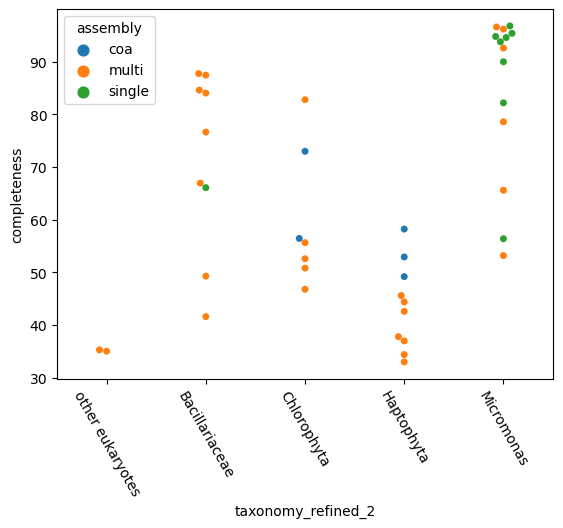

In [38]:
ax1 = sns.swarmplot(
    data = df_e061_v2, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single'], 
)

ax1.tick_params(axis='x', rotation=-60)

In [39]:
df_e061_v2[df_e061_v2.assembly == 'coa']

,genome,completeness,contamination,sample_id,batch,binning_and_type,binner,assembly,secondary_cluster,primary_cluster,bin_id,taxonomy_refined_2,tertiary_cluster,taxonomy_refined_3,usage
706,E06_1_mcl.11.13.split_1_v1.fna,52.94,5.88,E06_1,E06_1,manual_coa,manual,coa,29_1,29.0,E06_1_mcl.11.13.split_1_v1,Haptophyta,29_1,Haptophyta,5
708,E06_1_mcl.1.7.split_2_v1.fna,49.20,8.80,E06_1,E06_1,manual_coa,manual,coa,37_1,37.0,E06_1_mcl.1.7.split_2_v1,Haptophyta,37_1,Haptophyta,5
709,E06_1_mcl.1.split_1_v1.fna,73.00,3.20,E06_1,E06_1,manual_coa,manual,coa,40_1,40.0,E06_1_mcl.1.split_1_v1,Chlorophyta,40_1,Chlorophyta,5
710,E06_1_mcl.1.split_2_v1.fna,73.00,3.20,E06_1,E06_1,manual_coa,manual,coa,0_0,0_0,E06_1_mcl.1.split_2_v1,NaN,40_1,Chlorophyta,2
712,E06_1_mcl.2.split_1_v1.fna,56.45,0.81,E06_1,E06_1,manual_coa,manual,coa,36_7,36.0,E06_1_mcl.2.split_1_v1,Chlorophyta,36_7,Chlorophyta,5
714,E06_1_mcl.3.split_1_v1.fna,58.23,8.86,E06_1,E06_1,manual_coa,manual,coa,38_0,38.0,E06_1_mcl.3.split_1_v1,Haptophyta,38_0,Haptophyta,5


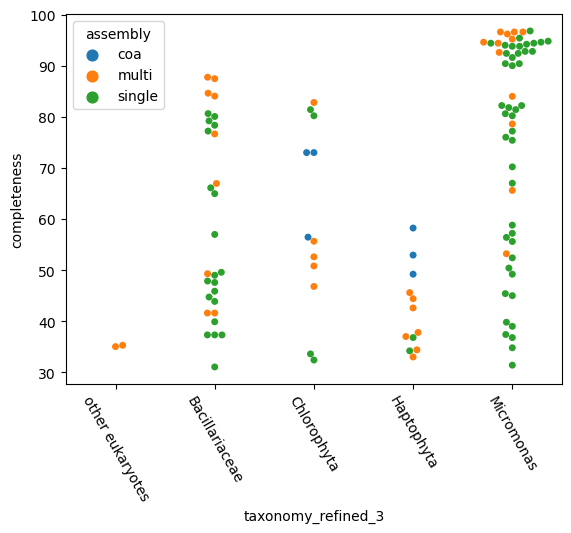

In [40]:
ax1 = sns.swarmplot(
    data = df_e061_v2, 
    y = 'completeness', 
    x = 'taxonomy_refined_3', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single']
)

ax1.tick_params(axis='x', rotation=-60)

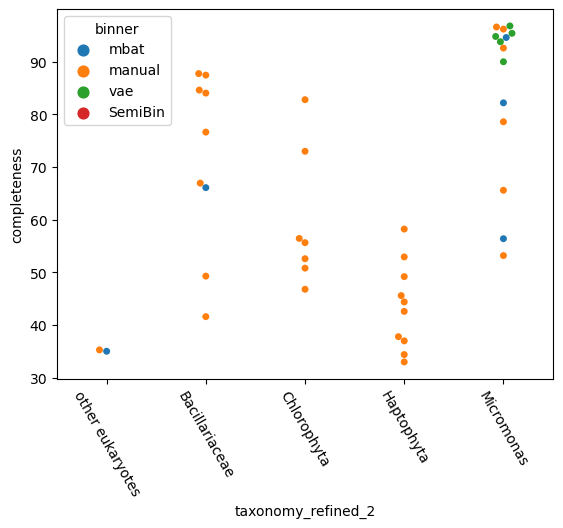

In [41]:
ax1 = sns.swarmplot(
    data = df_e061_v2, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'binner', 
)

ax1.tick_params(axis='x', rotation=-60)

In [66]:
df_e061_v3 = df_e061_v2[
    ~df_e061_v2.taxonomy_refined_2.isna()
].sort_values(
    'contamination', ascending = False
).groupby('tertiary_cluster').first().reset_index()

df_i041_v3 = df_i041_v2[
    ~df_i041_v2.taxonomy_refined_2.isna()
].sort_values(
    'contamination', ascending = False
).groupby('tertiary_cluster').first().reset_index()

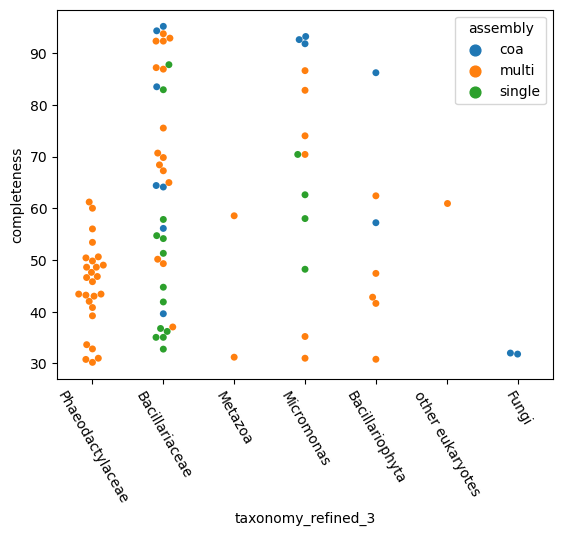

In [44]:
ax1 = sns.swarmplot(
    data = df_i041_v2, 
    y = 'completeness', 
    x = 'taxonomy_refined_3', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single'], 
)

ax1.tick_params(axis='x', rotation=-60)

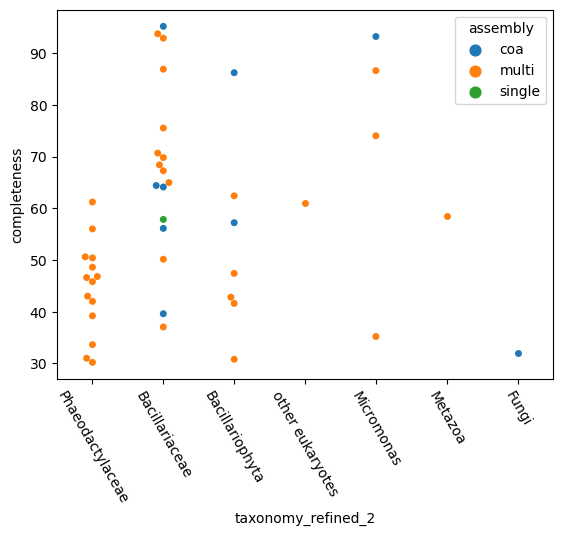

In [45]:
ax1 = sns.swarmplot(
    data = df_i041_v2, 
    y = 'completeness', 
    x = 'taxonomy_refined_2', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single']
)

ax1.tick_params(axis='x', rotation=-60)

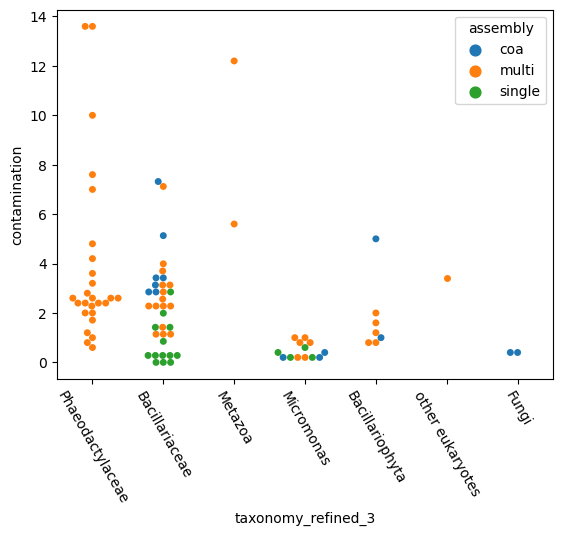

In [46]:
ax1 = sns.swarmplot(
    data = df_i041_v2, 
    y = 'contamination', 
    x = 'taxonomy_refined_3', 
    hue = 'assembly', 
    hue_order = ['coa', 'multi', 'single']
)

ax1.tick_params(axis='x', rotation=-60)

In [47]:
df_e061_v2.groupby('binning_and_type').describe()

completeness                                                \
                        count       mean        std    min      25%     50%   
binning_and_type                                                              
SemiBin_single           16.0  56.656875  18.889136  34.80  39.6675  48.715   
manual_coa                6.0  60.470000  10.187184  49.20  53.8175  57.340   
manual_multi             38.0  67.692368  23.780803  33.00  44.7000  71.795   
mbat_multi                1.0  35.030000        NaN  35.03  35.0300  35.030   
mbat_single              45.0  63.336889  21.494400  31.05  45.0000  64.960   
vae_single               10.0  92.800000   4.379751  81.40  93.0500  94.300   

                                 contamination            ...               \
                      75%    max         count      mean  ...   75%    max   
binning_and_type                                          ...                
SemiBin_single    77.0500  82.20          16.0  0.140625  ...  0.20   0.57   
manual_coa        69.3075  73.00           6.0  5.125000  ...  8.07   8.86   
manual_multi      91.7000  96.60          38.0  3.227632  ...  5.41  14.71   
mbat_multi        35.0300  35.03           1.0  6.370000  ...  6.37   6.37   
mbat_single       80.6300  94.60          45.0  0.973778  ...  1.42   6.84   
vae_single        94.7000  96.80          10.0  1.060000  ...  1.15   5.00   

                 usage                                               
                 count      mean       std  min  25%  50%  75%  max  
binning_and_type                                                     
SemiBin_single    16.0  2.000000  0.000000  2.0  2.0  2.0  2.0  2.0  
manual_coa         6.0  4.500000  1.224745  2.0  5.0  5.0  5.0  5.0  
manual_multi      38.0  4.131579  1.378818  2.0  2.0  5.0  5.0  5.0  
mbat_multi         1.0  5.000000       NaN  5.0  5.0  5.0  5.0  5.0  
mbat_single       45.0  2.266667  0.863397  2.0  2.0  2.0  2.0  5.0  
vae_single        10.0  3.500000  1.581139  2.0  2.0  3.5  5.0  5.0  

[6 rows x 24 columns]

In [48]:
df_e061_v2.shape, df_i041_v2.shape

((116, 15), (91, 15))

In [49]:
df_e061_v2[df_e061_v2.assembly == 'single'].groupby('taxonomy_refined_3').describe()

completeness                                              \
                          count       mean        std    min     25%    50%   
taxonomy_refined_3                                                            
Bacillariaceae             20.0  54.743500  16.792781  31.05  42.875  48.43   
Chlorophyta                 4.0  56.900000  27.606038  32.40  33.300  56.90   
Haptophyta                  2.0  35.500000   1.838478  34.20  34.850  35.50   
Micromonas                 44.0  73.245455  21.600037  31.40  54.800  81.00   

                                   contamination          ...              \
                        75%    max         count    mean  ...   75%   max   
taxonomy_refined_3                                        ...               
Bacillariaceae      68.8775  80.63          20.0  1.2235  ...  1.99  6.84   
Chlorophyta         80.5000  81.40           4.0  2.3000  ...  3.95  5.00   
Haptophyta          36.1500  36.80           2.0  4.6000  ...  5.30  6.00   
Micromonas          92.8000  96.80          44.0  0.3000  ...  0.20  2.40   

                   usage                                               
                   count      mean       std  min  25%  50%  75%  max  
taxonomy_refined_3                                                     
Bacillariaceae      20.0  2.150000  0.670820  2.0  2.0  2.0  2.0  5.0  
Chlorophyta          4.0  2.000000  0.000000  2.0  2.0  2.0  2.0  2.0  
Haptophyta           2.0  2.000000  0.000000  2.0  2.0  2.0  2.0  2.0  
Micromonas          44.0  2.545455  1.170461  2.0  2.0  2.0  2.0  5.0  

[4 rows x 24 columns]

In [50]:
df_e061_v2.sort_values(
    'completeness', ascending = False
).groupby(
    ['tertiary_cluster', 'taxonomy_refined_3']
).first().reset_index().groupby('assembly').describe()

completeness                                                      \
                count       mean        std   min     25%     50%     75%   
assembly                                                                    
coa               4.0  54.205000   3.995452  49.2  52.005  54.695  56.895   
multi            26.0  57.443846  19.557892  33.0  41.850  51.705  78.110   
single            3.0  73.100000  21.090045  56.4  61.250  66.100  81.450   

                contamination            ...               usage            \
            max         count      mean  ...    75%    max count      mean   
assembly                                 ...                                 
coa       58.23           4.0  6.087500  ...  8.815   8.86   4.0  5.000000   
multi     87.75          26.0  4.008077  ...  6.100  14.71  26.0  4.884615   
single    96.80           3.0  2.946667  ...  4.320   6.84   3.0  5.000000   

                                             
               std  min  25%  50%  75%  max  
assembly                                     
coa       0.000000  5.0  5.0  5.0  5.0  5.0  
multi     0.588348  2.0  5.0  5.0  5.0  5.0  
single    0.000000  5.0  5.0  5.0  5.0  5.0  

[3 rows x 24 columns]

In [51]:
df_e061_v2.sort_values(
    'completeness', ascending = False
).groupby(
    ['tertiary_cluster', 'taxonomy_refined_3']
).first().reset_index(
).sort_values(
    'completeness', ascending = False
).groupby('binner').describe()

completeness                                                        \
              count   mean        std    min     25%    50%    75%    max   
binner                                                                      
manual         29.0  57.77  18.074414  33.00  44.400  52.94  76.64  87.75   
mbat            3.0  52.51  15.896078  35.03  45.715  56.40  61.25  66.10   
vae             1.0  96.80        NaN  96.80  96.800  96.80  96.80  96.80   

       contamination            ...               usage                      \
               count      mean  ...    75%    max count      mean       std   
binner                          ...                                           
manual          29.0  4.213448  ...  6.200  14.71  29.0  4.896552  0.557086   
mbat             3.0  4.470000  ...  6.605   6.84   3.0  5.000000  0.000000   
vae              1.0  1.800000  ...  1.800   1.80   1.0  5.000000       NaN   

                                 
        min  25%  50%  75%  max  
binner                           
manual  2.0  5.0  5.0  5.0  5.0  
mbat    5.0  5.0  5.0  5.0  5.0  
vae     5.0  5.0  5.0  5.0  5.0  

[3 rows x 24 columns]

In [52]:
xtmp = df_e061_v2.sort_values(
    'completeness', ascending = False
).groupby(
    ['binner', 'tertiary_cluster', 'taxonomy_refined_3']
).first().reset_index(
).sort_values(
    'completeness', ascending = False
)

clusters = ['10_12',
 '10_21',
 '10_31',
 '10_34',
 '10_39',
 '10_6',
 '10_7',
 '10_9',
 '11_2',
 '37_11',
 '37_4',
 '40_1',
 '40_2',
 '41_15',
 '41_17',
 '41_19',
 '41_2',
 '41_6'
]


xtmp[xtmp.tertiary_cluster.isin(clusters)].groupby(['tertiary_cluster', 'binner']).describe()
#improvements = [7, 12, 10, 2, 10, 5, 6, 7, -25, 10, 2, 20, 31, 42, -0.2, 3, 31]
contaminations = [0.3, 1.4, 0.5, 0.0, 3.2, 2.2, 1.1, 0.9, 0.8, -1.2, 2.4, 1.2, 0.8, 0.4, 0.0, 0.2, 0.4]
#np.mean(improvements)

np.mean(contaminations), np.std(contaminations)

(0.8588235294117647, 1.0041436641586183)

In [53]:
df_i041_v2.groupby(['taxonomy_refined_3', 'assembly']).describe()

completeness                                       \
                                   count       mean        std    min     25%   
taxonomy_refined_3 assembly                                                     
Bacillariaceae     coa               7.0  71.018571  20.742933  39.60  60.100   
                   multi            15.0  73.220667  17.894469  37.04  66.100   
                   single           13.0  50.075385  17.830764  32.76  36.180   
Bacillariophyta    coa               2.0  71.700000  20.506097  57.20  64.450   
                   multi             5.0  45.000000  11.473448  30.80  41.600   
Fungi              coa               2.0  31.900000   0.141421  31.80  31.850   
Metazoa            multi             2.0  44.870000  19.332299  31.20  38.035   
Micromonas         coa               3.0  92.533333   0.702377  91.80  92.200   
                   multi             6.0  63.333333  24.169954  31.00  44.000   
                   single            4.0  59.800000   9.273618  48.20  55.550   
Phaeodactylaceae   multi            26.0  44.915000   8.452241  30.20  41.100   
other eukaryotes   multi             1.0  61.000000        NaN  61.00  61.000   

                                                  contamination            \
                               50%     75%    max         count      mean   
taxonomy_refined_3 assembly                                                 
Bacillariaceae     coa       64.39  88.890  95.16           7.0  4.017143   
                   multi     70.66  89.745  93.73          15.0  2.696000   
                   single    44.73  54.700  87.75          13.0  0.763846   
Bacillariophyta    coa       71.70  78.950  86.20           2.0  3.000000   
                   multi     42.80  47.400  62.40           5.0  1.280000   
Fungi              coa       31.90  31.950  32.00           2.0  0.400000   
Metazoa            multi     44.87  51.705  58.54           2.0  8.900000   
Micromonas         coa       92.60  92.900  93.20           3.0  0.266667   
                   multi     72.20  80.600  86.60           6.0  0.666667   
                   single    60.30  64.550  70.40           4.0  0.350000   
Phaeodactylaceae   multi     46.20  49.600  61.20          26.0  3.922692   
other eukaryotes   multi     61.00  61.000  61.00           1.0  3.400000   

                             ...                usage                      \
                             ...     75%    max count      mean       std   
taxonomy_refined_3 assembly  ...                                            
Bacillariaceae     coa       ...   4.275   7.32   7.0  4.142857  1.463850   
                   multi     ...   3.130   7.12  15.0  4.200000  1.373213   
                   single    ...   1.420   2.85  13.0  2.230769  0.832050   
Bacillariophyta    coa       ...   4.000   5.00   2.0  5.000000  0.000000   
                   multi     ...   1.600   2.00   5.0  5.000000  0.000000   
Fungi              coa       ...   0.400   0.40   2.0  3.500000  2.121320   
Metazoa            multi     ...  10.550  12.20   2.0  3.500000  2.121320   
Micromonas         coa       ...   0.300   0.40   3.0  3.000000  1.732051   
                   multi     ...   0.950   1.00   6.0  3.500000  1.643168   
                   single    ...   0.450   0.60   4.0  2.000000  0.000000   
Phaeodactylaceae   multi     ...   4.050  13.60  26.0  3.615385  1.525173   
other eukaryotes   multi     ...   3.400   3.40   1.0  5.000000       NaN   

                                                        
                             min   25%  50%   75%  max  
taxonomy_refined_3 assembly                             
Bacillariaceae     coa       2.0  3.50  5.0  5.00  5.0  
                   multi     2.0  3.50  5.0  5.00  5.0  
                   single    2.0  2.00  2.0  2.00  5.0  
Bacillariophyta    coa       5.0  5.00  5.0  5.00  5.0  
                   multi     5.0  5.00  5.0  5.00  5.0  
Fungi              coa       2.0  2.75  3.5 

In [54]:
ytmp = df_i041_v2.sort_values(
    'completeness', ascending = False
).groupby(
    ['binner', 'tertiary_cluster', 'taxonomy_refined_3']
).first().reset_index(
).sort_values(
    'completeness', ascending = False
)

#ytmp.groupby(['tertiary_cluster', 'taxonomy_refined_3', 'binner']).describe().head(60)

In [55]:
clusters2 = ['41_4', '41_25','41_2', '41_14', '33_2', '23_5', '23_4', '23_3', 
             '23_2', '22_9', '22_7', '22_2', '10_25', '10_26', '10_27', '11_1', '11_4',
             '20_1', '20_2', '20_3', '20_4', 
]


ytmp[
    ytmp.tertiary_cluster.isin(clusters2) & 
    (ytmp.taxonomy_refined_3 == 'Bacillariaceae')
].groupby(['binning_and_type']).describe()


completeness                                            \
                        count    mean        std    min     25%     50%   
binning_and_type                                                          
SemiBin_single            4.0  40.525   9.097818  35.04  35.895  36.465   
manual_coa                1.0  95.160        NaN  95.16  95.160  95.160   
manual_multi              1.0  50.140        NaN  50.14  50.140  50.140   
mbat_multi                5.0  70.828  15.500967  49.29  67.240  69.800   
vae_coa                   1.0  94.300        NaN  94.30  94.300  94.300   

                                contamination         ...             usage  \
                     75%    max         count   mean  ...   75%   max count   
binning_and_type                                      ...                     
SemiBin_single    41.095  54.13           4.0  0.140  ...  0.28  0.28   4.0   
manual_coa        95.160  95.16           1.0  3.130  ...  3.13  3.13   1.0   
manual_multi      50.140  50.14           1.0  1.140  ...  1.14  1.14   1.0   
mbat_multi        75.500  92.31           5.0  2.848  ...  3.70  3.99   5.0   
vae_coa           94.300  94.30           1.0  2.850  ...  2.85  2.85   1.0   

                                                          
                 mean       std  min  25%  50%  75%  max  
binning_and_type                                          
SemiBin_single    2.0  0.000000  2.0  2.0  2.0  2.0  2.0  
manual_coa        5.0       NaN  5.0  5.0  5.0  5.0  5.0  
manual_multi      5.0       NaN  5.0  5.0  5.0  5.0  5.0  
mbat_multi        3.8  1.643168  2.0  2.0  5.0  5.0  5.0  
vae_coa           2.0       NaN  2.0  2.0  2.0  2.0  2.0  

[5 rows x 24 columns]

In [56]:
ytmp.tertiary_cluster.nunique(), xtmp.tertiary_cluster.nunique()

(39, 32)

In [57]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/coassemblies_tmp/E06_1/megahit/final.contigs.fa

/gpfs/data/mock_lab/will/mosaic_tmp/coassemblies_tmp/E06_1/megahit/final.contigs.fa


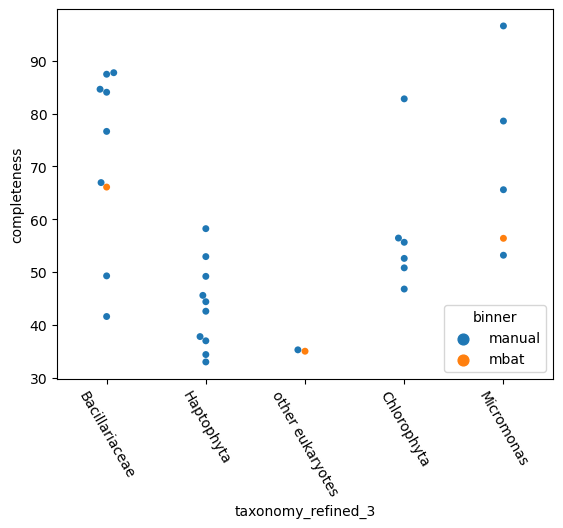

In [62]:
ax1 = sns.swarmplot(
    data = df_e061_v3, 
    y = 'completeness', 
    x = 'taxonomy_refined_3', 
    hue = 'binner', 
)

ax1.tick_params(axis='x', rotation=-60)

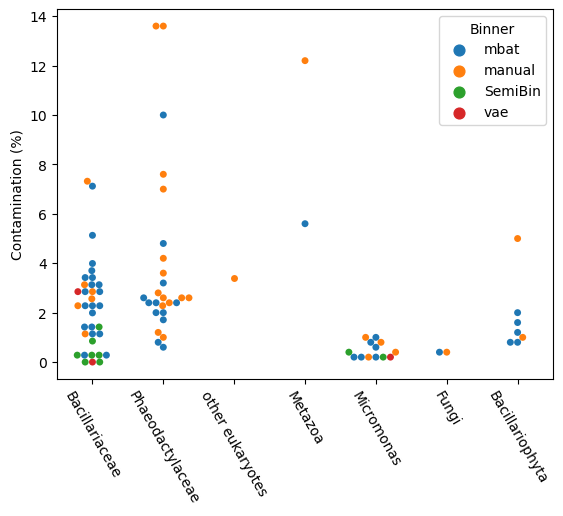

In [99]:
cc = 'contamination'
ab = 'binner'
tt = '3'


cc_upper = "C" + cc[1:]
ab_upper = ab[0].upper() + ab[1:]
ba_suffix = 'binner_' if ab == 'binner' else ''

hue_ord = None if ab == 'binner' else ['coa', 'multi', 'single']

order_e1 = ['other eukaryotes', 'Bacillariaceae', 'Chlorophyta', 'Haptophyta', 'Micromonas']
order_i1 = [
    'Bacillariaceae', 'Phaeodactylaceae', 'other eukaryotes', 'Metazoa', 'Micromonas', 'Fungi', 'Bacillariophyta'
]

ax1 = sns.swarmplot(
    data = df_i041_v2, 
    y = cc, 
    x = f"taxonomy_refined_{tt}", 
    hue = ab, 
    order = order_i1,
    hue_order = hue_ord, 
)
ax1.set(xlabel='', ylabel=f"{cc_upper} (%)")

ax1.tick_params(axis='x', rotation=-60)
plt.legend(title=ab_upper)
plt.savefig(f"/gpfs/home/qcf21tku/scratch/refine_chap/svgs/df_i041_{ba_suffix}tr{tt}_{cc}.svg")